In [95]:
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, LogisticRegression
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
import statsmodels.formula.api as smf
from itertools import product
from sklearn.metrics import (
    mean_absolute_error, root_mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, ConfusionMatrixDisplay,
)
from itertools import combinations
from scipy import sparse
from threadpoolctl import threadpool_limits

SEED = 42
SAMPLE_FRACTION = 0.0008 # 0.08%
DATA_PATH = "datasets/USDOT_1987_2025_Flights_Dataset/flights_2008_2025_cleaned.parquet"

Our data from 2008-2025 is about 1.5M entries. To enable effective modelling we sampled only 0.05% of it. Using a SEED to ensure reproducibility.

In [96]:
parquet = pq.ParquetFile(DATA_PATH)
sample_size = round(parquet.metadata.num_rows * SAMPLE_FRACTION)
rng = np.random.default_rng(SEED)
positions = np.sort(rng.choice(parquet.metadata.num_rows, sample_size, replace=False))

parts = []
offset = 0
for group in range(parquet.num_row_groups):
    end = offset + parquet.metadata.row_group(group).num_rows
    rows = positions[(positions >= offset) & (positions < end)] - offset
    if len(rows):
        table = parquet.read_row_group(group)
        parts.append(table.take(rows).to_pandas())
    offset = end
data = pd.concat(parts, ignore_index=True)
print(f"Sample: {len(data):,} flights")

Sample: 91,490 flights


In [97]:
sample = data.loc[(data["cancelled"] == 0) & (data["diverted"] == 0)  & (data["arrival_delay"].between(0,30))].copy()

numeric = ["distance", "scheduled_elapsed_time", "air_time"]
print(f"Eligible: {len(sample):,}; excluded: {len(data) - len(sample):,}")
sample[numeric].describe().round(2)

Eligible: 24,000; excluded: 67,490


,distance,scheduled_elapsed_time,air_time
count,24000.00,24000.00,24000.00
mean,812.49,139.73,115.25
std,600.46,73.62,72.87
min,31.00,29.00,11.00
25%,369.00,85.00,62.00
50%,646.00,121.00,97.00
75%,1055.00,170.00,147.00
max,4983.00,660.00,638.00


Then we now assess the amount of null or missing data in the features we selected. From the table bellow we see all features have no missing entries.

In [98]:
dict_cols = {}
columns = ['month', 'year', 'dayofweek', 'airline', 'origin_airport_id', 'distance', 'dest_airport_id', 'crs_dep_time_hhmm', 'scheduled_elapsed_time', 'scheduled_arrival_hhmm']
for cols in columns:
    dict_cols[cols] = sum(sample[cols].isna())

pd.DataFrame(list(dict_cols.items()), columns=['col_name', 'missing_rows'])

,col_name,missing_rows
0,month,0
1,year,0
2,dayofweek,0
3,airline,0
4,origin_airport_id,0
5,distance,0
6,dest_airport_id,0
7,crs_dep_time_hhmm,0
8,scheduled_elapsed_time,0
9,scheduled_arrival_hhmm,0


Since `crs_dep_time_hhmm` and `scheduled_arrival_hhmm` are stored in HH:MM format, we need to convert these columns into numerical representations to facilitate data visualization and statistical analysis.

We will convert each time into the **number of minutes elapsed since midnight**. For example, 00:00 will correspond to 0 minutes, 06:00 to 360 minutes, and 12:00 to 720 minutes.

Special consideration must be given to flights that cross midnight, particularly those arriving on the following calendar day. Since this conversion only represents the time of day, it does not account for changes in calendar date or differences between airport time zones. These factors will need to be considered separately when calculating elapsed time or comparing departure and arrival times.

In [99]:
def hhmm_to_minutes(series):
    # Convert values to strings and remove colons
    times = (
        series.astype("string")
        .str.strip()
        .str.replace(":", "", regex=False)
    )

    # Convert HHMM strings into numbers
    times = pd.to_numeric(times, errors="coerce")

    # Extract hours and minutes
    hours = times // 100
    minutes = times % 100

    # Check for valid time values
    valid = (
        hours.between(0, 23)
        & minutes.between(0, 59)
    )

    # Convert to minutes since midnight
    total_minutes = hours * 60 + minutes

    return total_minutes.where(valid)

In [100]:
sample['scheduled_arrival_minutes'] = hhmm_to_minutes(sample['scheduled_arrival_hhmm'])
sample['crs_dep_time_minutes'] = hhmm_to_minutes(sample['crs_dep_time_hhmm'])
sample.drop('crs_dep_time_hhmm', axis=1, inplace=True)
sample.drop('scheduled_arrival_hhmm', axis=1, inplace=True)

In [101]:
sample[['scheduled_arrival_minutes', 'crs_dep_time_minutes']].head()

,scheduled_arrival_minutes,crs_dep_time_minutes
14,655,575
18,984,900
20,745,570
21,735,555
22,1270,1095


Since we have a separate DataFrame containing the airport IDs and their corresponding airport codes, we will map the numerical airport IDs to their respective airport codes. This will make the data easier to interpret and allow us to treat airports as categorical features in our regression analysis, rather than continuous numerical variables.

In [102]:
airport_df = pd.read_csv('datasets/USDOT_1987_2025_Flights_Dataset/airports.csv')
airport_df = airport_df[['airport_id', 'airport_code']]

airport_dict = (
    airport_df
    .set_index("airport_id")["airport_code"]
    .to_dict()
)
sample['origin_airport'] = sample['origin_airport_id'].map(airport_dict)
sample['dest_airport'] = sample['dest_airport_id'].map(airport_dict)
sample.drop('dest_airport_id', axis=1, inplace=True)
sample.drop('origin_airport_id', axis=1, inplace=True)



In [103]:
airline_df = pd.read_csv('datasets/USDOT_1987_2025_Flights_Dataset/airlines.csv')
airline_df = airline_df[['IATA_CODE_Reporting_Airline', 'airline_name']]

airline_dict = (
    airline_df
    .set_index("IATA_CODE_Reporting_Airline")["airline_name"]
    .to_dict()
)

sample['airline_name'] = sample['airline'].map(airline_dict)
sample['airline_name'] = sample['airline_name'].str.title()

We now drop the remaining columns not being used

In [104]:
features = [
    'month', 
    'year', 
    'dayofweek', 
    'airline', 
    'origin_airport', 
    'distance', 
    'dest_airport', 
    'crs_dep_time_minutes', 
    'scheduled_elapsed_time', 
    'scheduled_arrival_minutes']


target = "arrival_delay"

model_data = sample[features + [target]].copy()


In [105]:
model_data.head()

,month,year,dayofweek,airline,origin_airport,distance,dest_airport,crs_dep_time_minutes,scheduled_elapsed_time,scheduled_arrival_minutes,arrival_delay
14,7,2008,4,9E,MEM,324.0,GPT,575,80.0,655,1.0
18,7,2008,4,9E,LEX,296.0,DTW,900,84.0,984,23.0
20,7,2008,7,9E,MEM,570.0,GSO,570,115.0,745,18.0
21,7,2008,1,AA,EWR,2454.0,LAX,555,360.0,735,3.0
22,7,2008,2,AA,ORD,647.0,RDU,1095,115.0,1270,20.0


## Multicollinearity

Now we review our features to asses multicolinearity

In [106]:
numerical_features = [
    "crs_dep_time_minutes",
    "scheduled_arrival_minutes",
    "scheduled_elapsed_time",
    'distance'
]

correlation_matrix = model_data[numerical_features].corr()

display(correlation_matrix)

,crs_dep_time_minutes,scheduled_arrival_minutes,scheduled_elapsed_time,distance
crs_dep_time_minutes,1.000000,0.708120,-0.031076,-0.025135
scheduled_arrival_minutes,0.708120,1.000000,0.030647,0.028581
scheduled_elapsed_time,-0.031076,0.030647,1.000000,0.984013
distance,-0.025135,0.028581,0.984013,1.000000


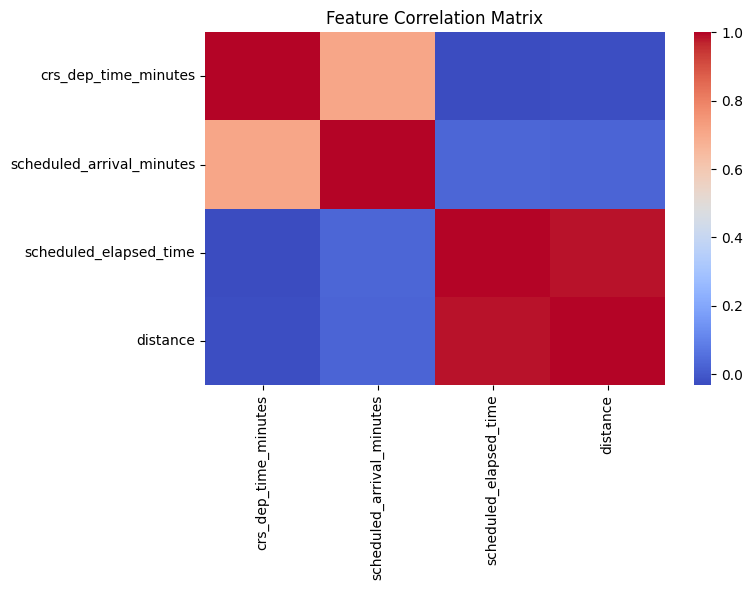

In [107]:
correlation_matrix = model_data[numerical_features].corr()

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    correlation_matrix, cmap = "coolwarm")

ax.set_title("Feature Correlation Matrix")

plt.tight_layout()
plt.show()

In [108]:
X = model_data[numerical_features]
X = X.astype("float64")

# Include an intercept
X = sm.add_constant(X)
vif_data = pd.DataFrame()
vif_data["Feature"] = X.columns

vif_data["VIF"] = [variance_inflation_factor(X.values, i)
                          for i in range(len(X.columns))]

# Exclude intercept and sort by VIF
vif_data = (
    vif_data[vif_data["Feature"] != "const"]
    .sort_values("VIF", ascending=False)
)

display(vif_data)

,Feature,VIF
3,scheduled_elapsed_time,31.666832
4,distance,31.616548
1,crs_dep_time_minutes,2.022570
2,scheduled_arrival_minutes,2.020783


### Multicollinearity Analysis — Numerical Features

Following the correlation analysis, Variance Inflation Factors (VIF) were calculated to investigate multicollinearity among the numerical predictors.

The results revealed substantial multicollinearity between Scheduled Elapsed Time and Distance, with VIF values of 30.08 and 30.02, respectively. These findings are consistent with their strong positive Pearson correlation (r = 0.9831), indicating that the two variables contain considerable overlapping information.

In contrast, Scheduled Departure Time and Scheduled Arrival Time returned VIF values of 2.18 and 2.12, respectively, indicating relatively manageable multicollinearity.

Based on these findings, no predictors will be automatically excluded at this stage. Instead, the potential redundancy between Scheduled Elapsed Time and Distance will be investigated during BIC model selection to determine whether including both variables provides sufficient improvement in model fit to justify their inclusion.

In [109]:
categorical_features = [
    'month', 
    'year', 
    'dayofweek', 
    'airline', 
    'origin_airport', 
    'dest_airport', ]

model_data[categorical_features].nunique()

month              12
year               18
dayofweek           7
airline            24
origin_airport    329
dest_airport      347
dtype: int64

### Restricting the Analysis to the Busiest Origin Airports

To reduce model complexity and focus our analysis on higher-traffic airports, we restricted the dataset to flights originating from the 20 busiest airports, based on flight counts within our sample. For the destination airports we will group them, each major airport will be its own group while the rest will be grouped into "Other"

This reduced the dataset from 55,980 to 29,615 observations, retaining approximately 52.9% of the original data. The number of unique origin airports decreased from 375 to 20, while the dataset still contains 339 unique destination airports.

This approach substantially reduces the number of parameters required to represent origin airports through one-hot encoding. However, it also limits the scope of our findings to flights originating from these 20 airports, rather than the entire airport network.

In [110]:
top_20_origins = (
    model_data["origin_airport"]
    .value_counts()
    .head(20)
    .index
)

display(
    model_data["origin_airport"]
    .value_counts()
    .head(20)
)

origin_airport
ATL    1413
ORD    1174
DFW    1110
DEN    1039
LAX     826
PHX     765
LAS     659
CLT     658
IAH     608
SFO     567
SEA     531
MCO     476
DTW     447
MSP     445
BWI     438
BOS     402
LGA     395
EWR     393
SLC     392
SAN     361
Name: count, dtype: int64

In [111]:
model_data_top20 = model_data.loc[
    model_data["origin_airport"].isin(top_20_origins)
].copy()

In [112]:
print("Original observations:", len(model_data))
print("Filtered observations:", len(model_data_top20))

print(
    "Percentage retained:",
    round(len(model_data_top20) / len(model_data) * 100, 2),
    "%"
)

print(
    "Unique origins:",
    model_data_top20["origin_airport"].nunique()
)

print(
    "Unique destinations:",
    model_data_top20["dest_airport"].nunique()
)

Original observations: 24000
Filtered observations: 13099
Percentage retained: 54.58 %
Unique origins: 20
Unique destinations: 308


In [113]:
top_20_dest = (
    model_data["dest_airport"]
    .value_counts()
    .head(20)
    .index
)

display(
    model_data["dest_airport"]
    .value_counts()
    .head(20)
)

dest_airport
ATL    1335
ORD    1019
DFW     945
DEN     908
LAX     797
PHX     706
LAS     617
IAH     589
CLT     571
SFO     531
SEA     500
DTW     486
MCO     454
MSP     447
SLC     432
EWR     411
BOS     411
LGA     374
BWI     367
JFK     348
Name: count, dtype: int64

In [114]:
model_data = model_data.loc[
    model_data["origin_airport"].isin(top_20_origins)
]

In [115]:
model_data["dest_airport_group"] = np.where(
    model_data["dest_airport"].isin(top_20_dest),
    model_data["dest_airport"],
    "Other"
)

By limiting our analysis to the 20 busiest origin airports and grouping destinations into the 20 busiest airports plus an "Other" category, we have significantly reduced the number of categorical variables that will be introduced during one-hot encoding.

This approach allows us to retain 29,615 observations, representing approximately 52.9% of our original dataset, while reducing the complexity associated with airport features. Our categorical predictors now consist of 102 categories, requiring 96 dummy variables when using one-hot encoding with a reference category omitted for each feature.

In [116]:
categorical_features = [
    'month', 
    'year', 
    'dayofweek', 
    'airline', 
    'origin_airport', 
    'dest_airport_group', ]

model_data[categorical_features].nunique()

month                 12
year                  18
dayofweek              7
airline               24
origin_airport        20
dest_airport_group    21
dtype: int64

In [117]:
final_features =[
    'distance', 
    'crs_dep_time_minutes', 
    'scheduled_elapsed_time', 
    'scheduled_arrival_minutes',    
    'month', 
    'year', 
    'dayofweek', 
    'airline', 
    'origin_airport', 
    'dest_airport_group']

In [118]:
sample['routes'] = sample['origin_airport'] + "-" + sample['dest_airport']

Lets see what happen if when we do a multiple linear regression with the features we selected and no polynomial terms:


$\text{Arrival Delay}(Y) = \beta_0 + \beta_1T_D +\sum_{j=1}^{p}\gamma_j C_j + \beta_2T_A + \beta_3T_E + \beta_4D$

Where:

$T_D$: Scheduled Departure Time


$T_A$: Scheduled Arrival Time


$T_E$: Scheduled Ellapsed TIme


$D$: Distance


$p$: Total number of categorical dummy variables.



$j$: Index identifying each dummy variable, from 1 to \(p\).



$\gamma_j$: Regression coefficient associated with dummy variable \(j\).



$C_j$: Dummy variable indicating whether an observation belongs to a particular category (0 or 1).

In [119]:
numerical_features = [
    "crs_dep_time_minutes",
    "scheduled_arrival_minutes",
    "scheduled_elapsed_time",
    'distance'
]
categorical_features = [
    'month', 
    'year', 
    'dayofweek', 
    'airline', 
    'origin_airport', 
    'dest_airport_group', ]

TARGET = 'arrival_delay'
independent_variables = numerical_features + categorical_features

X = model_data[independent_variables].copy()
y = model_data[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
)

In [120]:
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical_onehot", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_features),
        ("numerical", 'passthrough', numerical_features),
    ],
    remainder="drop",
)

linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regression", LinearRegression()),
    ]
)
model_linear = linear_model.fit(X_train, y_train)
model_linear

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('regression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical_onehot', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the

In [121]:
y_pred = linear_model.predict(X_test)

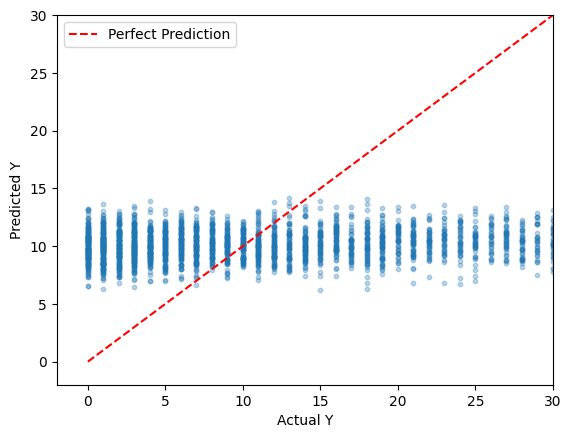

In [122]:
import matplotlib.pyplot as plt
import numpy as np

plt.scatter(y_test, y_pred, alpha=0.3, s=10)

# Perfect prediction reference line
low = min(y_test.min(), y_pred.min())
high = max(y_test.max(), y_pred.max())

plt.plot([low, high], [low, high], 'r--', label='Perfect Prediction')

plt.xlabel("Actual Y")
plt.ylabel("Predicted Y")
plt.xlim(-2, 30)
plt.ylim(-2, 30)
plt.legend()
plt.show()

In [123]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
mae_score = mean_absolute_error(y_test,y_pred)

print("RMSE:", rmse)
print("R²:", r2)
print("MAE:", mae_score)


RMSE: 8.382523202910988
R²: 0.017120873952189974
MAE: 7.029018324889419


In [124]:
numerical_features = [
    "crs_dep_time_minutes",
    "scheduled_arrival_minutes",
    "scheduled_elapsed_time",
    'distance'
]

degrees = [1, 2, 3]

degree_comb = list(product(degrees, repeat=len(numerical_features)))

print(degree_comb)
print(f"Total combinations: {len(degree_comb)}")

[(1, 1, 1, 1), (1, 1, 1, 2), (1, 1, 1, 3), (1, 1, 2, 1), (1, 1, 2, 2), (1, 1, 2, 3), (1, 1, 3, 1), (1, 1, 3, 2), (1, 1, 3, 3), (1, 2, 1, 1), (1, 2, 1, 2), (1, 2, 1, 3), (1, 2, 2, 1), (1, 2, 2, 2), (1, 2, 2, 3), (1, 2, 3, 1), (1, 2, 3, 2), (1, 2, 3, 3), (1, 3, 1, 1), (1, 3, 1, 2), (1, 3, 1, 3), (1, 3, 2, 1), (1, 3, 2, 2), (1, 3, 2, 3), (1, 3, 3, 1), (1, 3, 3, 2), (1, 3, 3, 3), (2, 1, 1, 1), (2, 1, 1, 2), (2, 1, 1, 3), (2, 1, 2, 1), (2, 1, 2, 2), (2, 1, 2, 3), (2, 1, 3, 1), (2, 1, 3, 2), (2, 1, 3, 3), (2, 2, 1, 1), (2, 2, 1, 2), (2, 2, 1, 3), (2, 2, 2, 1), (2, 2, 2, 2), (2, 2, 2, 3), (2, 2, 3, 1), (2, 2, 3, 2), (2, 2, 3, 3), (2, 3, 1, 1), (2, 3, 1, 2), (2, 3, 1, 3), (2, 3, 2, 1), (2, 3, 2, 2), (2, 3, 2, 3), (2, 3, 3, 1), (2, 3, 3, 2), (2, 3, 3, 3), (3, 1, 1, 1), (3, 1, 1, 2), (3, 1, 1, 3), (3, 1, 2, 1), (3, 1, 2, 2), (3, 1, 2, 3), (3, 1, 3, 1), (3, 1, 3, 2), (3, 1, 3, 3), (3, 2, 1, 1), (3, 2, 1, 2), (3, 2, 1, 3), (3, 2, 2, 1), (3, 2, 2, 2), (3, 2, 2, 3), (3, 2, 3, 1), (3, 2, 3, 2), (3, 2

In [125]:
hot_code = []
cat_formula = []
for cat in categorical_features:
    hot_code.append(f'C({cat})')
cat_formula.append(" + ".join(hot_code))
models = []
for combs in degree_comb:
    formula_terms = []

    for feature, degree in zip(numerical_features, combs):
        for power in range(1, degree + 1):
            if power == 1:
                formula_terms.append(feature)
            else:
                formula_terms.append(f"I({feature}**{power})")

    models.append(" + ".join(formula_terms + cat_formula))

In [126]:
results = []
train_df = pd.concat([X_train, y_train], axis=1)
test_df = pd.concat([X_test, y_test], axis=1)


for df in [train_df, test_df]:
    cols = df.select_dtypes(include=["Int8", "Int16", "Int32", "Int64"]).columns
    df[cols] = df[cols].astype("float64")

fitted_models = []
    
for i, (formula, combs) in enumerate(zip(models, degree_comb)):

    model = smf.ols(
        formula=f"arrival_delay ~ {formula}",
        data=train_df
    ).fit()
    fitted_models.append(model)
    predictions = model.predict(test_df)
    actual = test_df["arrival_delay"]

    results.append({
        "model_id": i,
        **dict(zip(numerical_features, combs)),
        "MAE": mean_absolute_error(actual, predictions),
        "RMSE": root_mean_squared_error(actual, predictions),
        "R2": r2_score(actual, predictions)
    })

results_df = pd.DataFrame(results)

In [127]:
display(results_df.sort_values('RMSE', ascending=True).head(5))
display(results_df.sort_values('MAE', ascending=True).head(5))
display(results_df.sort_values('R2', ascending=False).head(5))

,model_id,crs_dep_time_minutes,scheduled_arrival_minutes,scheduled_elapsed_time,distance,MAE,RMSE,R2
16,16,1,2,3,2,7.029712,8.382513,0.017123
13,13,1,2,2,2,7.029834,8.382560,0.017112
14,14,1,2,2,3,7.029471,8.382577,0.017108
9,9,1,2,1,1,7.029441,8.382697,0.017080
12,12,1,2,2,1,7.030237,8.383123,0.016980


,model_id,crs_dep_time_minutes,scheduled_arrival_minutes,scheduled_elapsed_time,distance,MAE,RMSE,R2
17,17,1,2,3,3,7.028686,8.383279,0.016944
44,44,2,2,3,3,7.028941,8.389057,0.015588
9,9,1,2,1,1,7.029441,8.382697,0.017080
14,14,1,2,2,3,7.029471,8.382577,0.017108
8,8,1,1,3,3,7.029522,8.384575,0.016640


,model_id,crs_dep_time_minutes,scheduled_arrival_minutes,scheduled_elapsed_time,distance,MAE,RMSE,R2
16,16,1,2,3,2,7.029712,8.382513,0.017123
13,13,1,2,2,2,7.029834,8.382560,0.017112
14,14,1,2,2,3,7.029471,8.382577,0.017108
9,9,1,2,1,1,7.029441,8.382697,0.017080
12,12,1,2,2,1,7.030237,8.383123,0.016980


In [128]:
airport_interactions = {
    "Origin × Departure Time":
        "C(origin_airport):crs_dep_time_minutes",

    "Origin × Distance":
        "C(origin_airport):distance",

    "Destination × Arrival Time":
        "C(dest_airport_group):scheduled_arrival_minutes",

    "Origin × Destination":
        "C(origin_airport):C(dest_airport_group)"
}

numerical_formula = numerical_features

categorical_formula = [
    f"C({feature})" for feature in categorical_features
]

baseline_formula = (
    TARGET + " ~ " +
    " + ".join(numerical_formula + categorical_formula)
)

In [129]:
results = []
fitted_models = {}

# Baseline + individual interactions
formulas = {"Baseline": baseline_formula}

for name, interaction in airport_interactions.items():
    formulas[name] = baseline_formula + " + " + interaction

# Fit and evaluate each model
for name, formula in formulas.items():

    model = smf.ols(
        formula=formula,
        data=train_df
    ).fit()

    predictions = model.predict(test_df)
    actual = test_df[TARGET]

    results.append({
        "Interaction": name,
        "MAE": mean_absolute_error(actual, predictions),
        "RMSE": root_mean_squared_error(actual, predictions),
        "R2": r2_score(actual, predictions),
        "Parameters": len(model.params)
    })

    fitted_models[name] = model

results_df = pd.DataFrame(results)
results_df.sort_values("RMSE")

,Interaction,MAE,RMSE,R2,Parameters
0,Baseline,7.030754,8.384530,0.016650,101
2,Origin × Distance,7.024922,8.385804,0.016351,120
1,Origin × Departure Time,7.034077,8.391603,0.014991,120
3,Destination × Arrival Time,7.041404,8.398611,0.013345,121
4,Origin × Destination,7.111280,8.535977,-0.019194,481


In [130]:
results_df.sort_values("RMSE")

,Interaction,MAE,RMSE,R2,Parameters
0,Baseline,7.030754,8.384530,0.016650,101
2,Origin × Distance,7.024922,8.385804,0.016351,120
1,Origin × Departure Time,7.034077,8.391603,0.014991,120
3,Destination × Arrival Time,7.041404,8.398611,0.013345,121
4,Origin × Destination,7.111280,8.535977,-0.019194,481


In [131]:
airline_interactions = {
    "airline × Departure Time":
        "C(airline):crs_dep_time_minutes",

    "airline × Distance":
        "C(airline):distance",

    "airline × Arrival Time":
        "C(airline):scheduled_arrival_minutes",

    "airline × Destination":
        "C(airline):C(dest_airport_group)"
}

numerical_formula = numerical_features

categorical_formula = [
    f"C({feature})" for feature in categorical_features
]

baseline_formula = (
    TARGET + " ~ " +
    " + ".join(numerical_formula + categorical_formula)
)

In [132]:
results = []
fitted_models = {}

# Baseline + individual interactions
formulas = {"Baseline": baseline_formula}

for name, interaction in airline_interactions.items():
    formulas[name] = baseline_formula + " + " + interaction

# Fit and evaluate each model
for name, formula in formulas.items():

    model = smf.ols(
        formula=formula,
        data=train_df
    ).fit()

    predictions = model.predict(test_df)
    actual = test_df[TARGET]

    results.append({
        "Interaction": name,
        "MAE": mean_absolute_error(actual, predictions),
        "RMSE": root_mean_squared_error(actual, predictions),
        "R2": r2_score(actual, predictions),
        "Parameters": len(model.params)
    })

    fitted_models[name] = model

results_df = pd.DataFrame(results)
results_df.sort_values("RMSE")

,Interaction,MAE,RMSE,R2,Parameters
1,airline × Departure Time,7.021746,8.382892,0.017034,124
0,Baseline,7.030754,8.384530,0.016650,101
3,airline × Arrival Time,7.039260,8.410838,0.010470,124
2,airline × Distance,7.044439,8.413494,0.009845,124
4,airline × Destination,7.089883,8.490914,-0.008462,561


In [133]:
departure_interactions = {
    "Airline × Departure Time":
        "C(airline):crs_dep_time_minutes",

    "Origin × Departure Time":
        "C(origin_airport):crs_dep_time_minutes",

    "Both Departure Interactions":
        "C(airline):crs_dep_time_minutes"
        " + C(origin_airport):crs_dep_time_minutes"
}
numerical_formula = numerical_features

categorical_formula = [
    f"C({feature})" for feature in categorical_features
]

baseline_formula = TARGET + " ~ " + " + ".join(
    numerical_formula + categorical_formula
)

formulas = {"Baseline": baseline_formula}

for name, interaction in departure_interactions.items():
    formulas[name] = baseline_formula + " + " + interaction




In [134]:
results = []
fitted_models = {}

for name, formula in formulas.items():

    model = smf.ols(
        formula=formula,
        data=train_df
    ).fit()

    predictions = model.predict(test_df)
    actual = test_df[TARGET]

    results.append({
        "Interaction": name,
        "MAE": mean_absolute_error(actual, predictions),
        "RMSE": root_mean_squared_error(actual, predictions),
        "R2": r2_score(actual, predictions),
        "Parameters": len(model.params)
    })

    fitted_models[name] = model

results_df = pd.DataFrame(results)

display(results_df.sort_values("RMSE"))

,Interaction,MAE,RMSE,R2,Parameters
1,Airline × Departure Time,7.021746,8.382892,0.017034,124
0,Baseline,7.030754,8.384530,0.016650,101
2,Origin × Departure Time,7.034077,8.391603,0.014991,120
3,Both Departure Interactions,7.033045,8.396160,0.013920,143


In [135]:
from sklearn.model_selection import KFold
from sklearn.metrics import (
    mean_absolute_error,
    root_mean_squared_error,
    r2_score
)

import statsmodels.formula.api as smf
import pandas as pd
import numpy as np

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

cv_results = []

for name, formula in formulas.items():

    fold_metrics = []

    for train_idx, val_idx in cv.split(train_df):

        # Split training data into folds
        fold_train = train_df.iloc[train_idx]
        fold_val = train_df.iloc[val_idx]

        # Fit model
        model = smf.ols(
            formula=formula,
            data=fold_train
        ).fit()

        # Predict
        predictions = model.predict(fold_val)
        actual = fold_val[TARGET]

        # Store fold metrics
        fold_metrics.append({
            "MAE": mean_absolute_error(actual, predictions),
            "RMSE": root_mean_squared_error(actual, predictions),
            "R2": r2_score(actual, predictions)
        })

    fold_df = pd.DataFrame(fold_metrics)

    # Store average performance and variation
    cv_results.append({
        "Interaction": name,
        "MAE_mean": fold_df["MAE"].mean(),
        "MAE_std": fold_df["MAE"].std(),
        "RMSE_mean": fold_df["RMSE"].mean(),
        "RMSE_std": fold_df["RMSE"].std(),
        "R2_mean": fold_df["R2"].mean(),
        "R2_std": fold_df["R2"].std()
    })

cv_results_df = pd.DataFrame(cv_results)

display(cv_results_df.sort_values("RMSE_mean"))

,Interaction,MAE_mean,MAE_std,RMSE_mean,RMSE_std,R2_mean,R2_std
0,Baseline,6.856127,0.096281,8.219418,0.112265,0.003750,0.005932
2,Origin × Departure Time,6.858342,0.095736,8.227699,0.112425,0.001747,0.004714
1,Airline × Departure Time,6.863564,0.092663,8.231102,0.109167,0.000913,0.004505
3,Both Departure Interactions,6.866202,0.089254,8.237824,0.106082,-0.000725,0.003658
